<a href="https://colab.research.google.com/github/FatherNurt/FPDP-Engine/blob/MAIN/Hydrogen_Phase_Geometry_Lab_v0_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hydrogen Phase–Geometry Correspondence Lab v0.1
**27 November 2026 | C9 prerequisite | computational control, not new physics**
Atomic units: length in bohr, energy in hartree. Clamped protons, nonrelativistic one electron, no external field, frozen hydrogen 1s orbitals. Hamiltonian $H=-\nabla^2/2-1/r_A-1/r_B+1/R$. Trial states $\psi_\theta=(\phi_A+e^{i\theta}\phi_B)/\sqrt{2(1+S\cos\theta)}$. Electronic matrix elements are $h=-1/2+J$, $k=-S/2+K$, with $J=-1/R+(1+1/R)e^{-2R}$, $K=-(1+R)e^{-R}$. Total energy $E_\theta=(h+k\cos\theta)/(1+S\cos\theta)+1/R$. Relative phase is a trial-state parameter in a real basis, not a new physical force. Only 0 and pi are stationary eigenstates of this projected Hamiltonian. No prescribed equilibrium distance or angular lattice. Reference: https://mochizuki-tus.github.io/QM_Textbook_EN/ch39_molecular_orbital_h2plus.html (minimal LCAO benchmark).

In [ ]:
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.linalg import eigh
from scipy.integrate import quad
import matplotlib.pyplot as plt
BOHR_A=0.529177210903
HARTREE_EV=27.211386245988
def matrices(R):
    S=np.exp(-R)*(1+R+R*R/3)
    J=-1/R+(1+1/R)*np.exp(-2*R)
    K=-(1+R)*np.exp(-R)
    return S,-0.5+J,-0.5*S+K
def energy(R,theta=0):
    S,h,k=matrices(R); c=np.cos(theta)
    return (h+k*c)/(1+S*c)+1/R
res=minimize_scalar(energy,bounds=(0.3,12),method='bounded',options={'xatol':1e-12})
R0=res.x; E0=res.fun
print(f'R = {R0:.9f} bohr = {R0*BOHR_A:.9f} angstrom')
print(f'E = {E0:.12f} hartree; D_e = {(-0.5-E0)*HARTREE_EV:.9f} eV')
for step in [1e-3,1e-4]:
    force=-(energy(R0+step)-energy(R0-step))/(2*step)
    curvature=(energy(R0+step)-2*E0+energy(R0-step))/step**2
    print(f'step={step}: force={force:.3e}, curvature={curvature:.9f}')
    assert abs(force)<1e-6 and curvature>0
assert res.success and E0<-.5

R = 2.492830372 bohr = 1.319149023 angstrom
E = -0.564830992371 hartree; D_e = 1.764141174 eV
step=0.001: force=2.464e-08, curvature=0.062833093
step=0.0001: force=2.653e-09, curvature=0.062833061


In [ ]:
# Independent generalized eigensolver and numerical overlap integral in prolate coordinates.
Rgrid=np.geomspace(.3,40,1000)
errors=[]
for R in Rgrid:
    S,h,k=matrices(R)
    vals=eigh([[h,k],[k,h]],[[1,S],[S,1]],eigvals_only=True)+1/R
    errors.append(np.max(np.abs(vals-[energy(R),energy(R,np.pi)])))
assert max(errors)<1e-11
for R in [.5,R0,5.,10.]:
    # dV = R^3/8*(xi^2-eta^2) dxi deta dphi; phi_A phi_B=exp(-R*xi)/pi
    overlap=R**3/4*quad(lambda xi: np.exp(-R*xi)*(2*xi**2-2/3),1,np.inf,epsabs=1e-12)[0]
    assert abs(overlap-matrices(R)[0])<1e-10
assert np.all(energy(Rgrid,np.pi)>-.5)
assert abs(energy(40)+.5)<1e-12
print('PASS: eigenvalue agreement, overlap quadrature, sampled antibonding and dissociation checks')
print('Maximum eigenvalue error:',max(errors))

PASS: eigenvalue agreement, overlap quadrature, sampled antibonding and dissociation checks
Maximum eigenvalue error: 4.884981308350689e-15


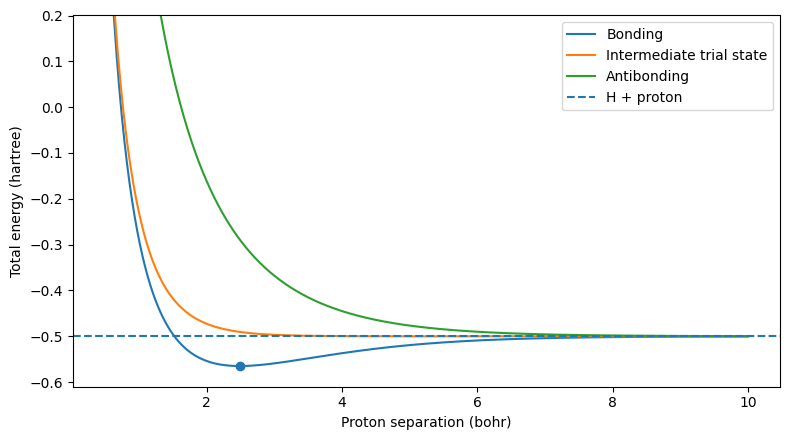

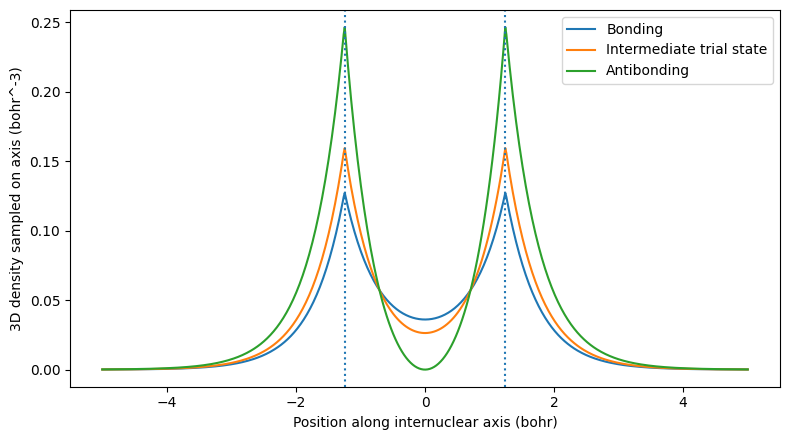

Midpoint density bonding: 0.0360493097141233


In [ ]:
R=np.linspace(.5,10,500)
plt.figure(figsize=(8,4.5))
for theta,label in [(0,'Bonding'),(np.pi/2,'Intermediate trial state'),(np.pi,'Antibonding')]:
    plt.plot(R,energy(R,theta),label=label)
plt.axhline(-.5,ls='--',label='H + proton'); plt.scatter([R0],[E0]); plt.ylim(-.61,.2)
plt.xlabel('Proton separation (bohr)'); plt.ylabel('Total energy (hartree)'); plt.legend(); plt.tight_layout(); plt.show()
z=np.linspace(-5,5,600); A=np.exp(-abs(z+R0/2))/np.sqrt(np.pi); B=np.exp(-abs(z-R0/2))/np.sqrt(np.pi)
S=matrices(R0)[0]
plt.figure(figsize=(8,4.5))
for theta,label in [(0,'Bonding'),(np.pi/2,'Intermediate trial state'),(np.pi,'Antibonding')]:
    rho=abs(A+np.exp(1j*theta)*B)**2/(2*(1+S*np.cos(theta)))
    plt.plot(z,rho,label=label)
for p in [-R0/2,R0/2]: plt.axvline(p,ls=':')
plt.xlabel('Position along internuclear axis (bohr)'); plt.ylabel('3D density sampled on axis (bohr^-3)'); plt.legend(); plt.tight_layout(); plt.show()
print('Midpoint density bonding:',2*np.exp(-R0)/(np.pi*(1+S)))

## Disposition
The minimum is an output of the variational energy surface, not a prescribed spacing. The two-center axis is assumed; absolute orientation is degenerate in zero field. The minimal basis overestimates the benchmark clamped-nuclei equilibrium (~2 bohr) and underestimates its dissociation energy (~2.79 eV). No field perturbation, nuclear dynamics, many-body coherence or lattice formation is demonstrated. Next: basis convergence, then independent field perturbation and force calculation. Numerical checks are not global analytic proofs. C9 is unchanged.